## 1. A Matriz elástica

### 1.a
Vamos considerar que a massa $i-1$ está à esquerda de i e a massa $i+1$, à direita, assim como é ilustrado na figura.

O comprimento das mola à esquerda e à direita de $x_i$ são dados por
$$L_{i_{e}} = x_i - x_{i-1} + L$$
$$L_{i_{d}} = x_i - x_{i+1} + L$$

Disso, obtemos a deformação de cada mola
$$\Delta L_{i_{e}} = L_{i_{e}} - L = x_i - x_{i-1}$$
$$\Delta L_{i_{d}} = L_{i_{d}} - L = x_i - x_{i+1}$$

Pela lei de Hooke, a força exercida por cada mola é dada por 
$$F_{i_{e}} = -k\, \Delta L_{i_{e}} = -k(x_i - x_{i-1})$$
$$F_{i_{d}} = -k\, \Delta L_{i_{d}} = -k(x_i - x_{i+1})$$

Por fim, a mola fixa de constante $k_i$ exerce uma força $F_{i_{f}}$ dada por
$$F_{i_{f}} = -k_i x_i$$

Ao final, obtemos que a força resultante $F_i$ que atua sobre a massa $i$ é dada por
$$
\begin{align*}
    F_i &= F_{i_{e}} + F_{i_{d}} + F_{i_{f}} \\
        &= -k(2\,x_i - x_{i-1} - x_{i+1}) - k_i\,x_i \\
        &= -k\left[
                \left(
                    2 +\frac{k_i}{k}
                \right)x_i
                - x_{i-1} - x_{i+1}
            \right]
\end{align*}
$$

Pela segunda lei de Newton
$$m\, \ddot{x_i} = F_i$$
$$
\Rightarrow
m\, \ddot{x}_i =
-k\left[
    \left(
        2 +\frac{k_i}{k}
    \right)x_i
    - x_{i-1} - x_{i+1}
\right]
$$

Agora, para a massa $1$, temos
$$\Delta L_{1_{d}} = x_1 - x_{2}$$
$$\Delta L_{1_{f}} = x_1$$
e
$$F_{1_{d}} = -k(x_1 - x_{2})$$
$$F_{1_{f}} = -k_1\,x_1$$
Portanto
$$F_1 = F_{1_{d}} + F_{1_{f}} = -k(x_1 - x_{2}) - k_1\,x_1$$

Pela segunda lei de Newton
$$
m\, \ddot{x}_1 =
-k\left[
    \left(
        1 + \frac{k_1}{k}
    \right)x_1
    - x_{2}
\right]
$$

Analogamente
$$
m\, \ddot{x}_N =
-k\left[
    \left(
        1 + \frac{k_N}{k}
    \right)x_N
    - x_{N-1}
\right]
$$

A explicação para que $L$ não apareça na equação final é que, pela lei de Hooke, a força só depende da deformação da mola em relação ao seu comprimento relaxado, i. e., o quanto cada par de massas conectadas à mola se deslocou em relação à posição de equilíbrio.

Na prática, ao cortar uma mola ou obter outra de tamanho maior do mesmo material, o comportamento do sistema pode mudar. Entretanto, o motivo disso é que a própria constante elástica $k$ da mola se altera quando o seu comprimento relaxado é modificado. Como estamos assumindo que $k$ é dado no nosso sistema, o comprimento da mola não influencia a aceleração final.

### 1.b
Definido $A_{ij}$ por
$$
A_{ij} =
\left(
    2 + \frac{k_i}{k}
\right)\delta_{ij}
- \delta_{i,j+1}
- \delta_{i,j-1}
- \delta_{i1}\delta_{j1}
- \delta_{iN}\delta_{jN}
$$

Temos que
$$-k\,A_{i,i-1}\,x_{i-1}=-kx_{i-1},\quad i > 1$$
$$
-k\,A_{ii}\,x_{i}
=
-k\left(
    2 + \frac{k_i}{k}
\right)x_{i}, \quad 1 < i < N
$$
$$-k\,A_{i,i+1}\,x_{i+1}=-kx_{i+1},\quad i < N$$

Em particular
$$
\begin{align*}
-k\,A_{11}\,x_{1}
&=
-k\left(
    2 + \frac{k_i}{k}
\right)x_{1}-kx_{1}\\
&=
-k\left(
    1 + \frac{k_1}{k}
\right)x_{1}
\end{align*}
$$
$$
\begin{align*}
-k\,A_{NN}\,x_{N}
&=
-k\left(
    2 + \frac{k_N}{k}
\right)x_{N}-kx_{N}\\
&=
-k\left(
    1 + \frac{k_1}{k}
\right)x_{N}
\end{align*}
$$

Assim, para todo $i \leq N$
$$
\begin{align*}
-k\sum_{j=1}^N
    A_{ij}\,x_j
\end{align*}
=
F_i
=
m\, \ddot{x}_i
$$
É possivel verificar isso ao perceber que, para $1 < i < N$ a soma final é a soma dos termos $i-1$, $i$ e $i+1$, pois todos os outros termos são iguais a 0. Para $i=1$ e $i=N$, o termo de correção "subtrai o excesso" de $A_{ii}$.

Dado que
$$
\vec{x} =
\sum_{i=1}^N
    x_i\,\hat{x}_i
$$

Temos
$$
\begin{align*}
m\,\ddot{\vec{x}}
&=
\sum_{i=1}^N
    m\,\ddot{x}_i\,\hat{x}_i \\
&=
\sum_{i=1}^N
    -k\sum_{j=1}^N
    A_{ij}\,x_j\,\hat{x}_i \\
&=
-k\,\mathsf{A}\,\vec{x}
\end{align*}
$$

### 1.c

In [1]:
import numpy as np

np.set_printoptions(precision=3, suppress=True)

N = 10
k = 1

k_n = np.random.uniform(0, 2, N)


def construir_matriz(N, k_n=None, k=1, m=1, L=1):
    """
    Constrói a matriz A de um cenário do problema com os parâmetros dados
    """
    if k_n is None:
        k_n = np.zeros(N)

    cenario = dict()
    cenario["A"] = np.diag(2. + k_n / k)
    cenario["A"] += np.diag(-np.ones(N - 1), 1)
    cenario["A"] += np.diag(-np.ones(N - 1), -1)
    cenario["A"][0, 0] -= 1
    cenario["A"][-1, -1] -= 1

    cenario["k"] = k
    cenario["m"] = m
    cenario["L"] = L

    return cenario

teste = construir_matriz(N, k_n, k=k)
caso1 = construir_matriz(N, k=k)

k_n_caso2 = np.zeros(N)
k_n_caso2[0] = k
k_n_caso2[-1] = k

caso2 = construir_matriz(N, k_n_caso2)

print(caso2["A"])

[[ 2. -1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-1.  2. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  2. -1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -1.  2. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  2. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  2. -1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  2. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -1.  2. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. -1.  2. -1.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. -1.  2.]]


## 2

### 2.a

O resultado de álgebra linear que estamos utilizando aqui é o Teorema Espectral. Pela construção da matriz A,
$$A_{ij} = A_{ji}.$$
Portanto, A é simétrica e pode ser diagonalizada na forma
$$A=PDP^{T},$$
onde $D$ é a matriz diagonal formada pelos autovalores de $A$ e $P$ é formado pela base $\mathcal{U}$ de $N$ autovetores ortonormais de $A$

In [ ]:
def inserir_autovalores(cenario):
    """
    Modifica o dicionário de um cenário, inserindo os autovalores e autovetores correspondentes
    """
    cenario["lambda_n"], cenario["u_n"] = np.linalg.eigh(cenario["A"])
    cenario["lambda_n"] = np.maximum(cenario["lambda_n"], 0)

inserir_autovalores(teste)

import itertools

for i, j in itertools.combinations_with_replacement(teste["u_n"].T, 2):
    temp = i @ j
    print(np.allclose(temp, np.zeros_like(temp)))


### 2.b

Para entender o que cada espectro significa, recordemos o que é a diagonalização, aplicando-a à equação do movimento que encontramos em 1.b:
$$m\,\ddot{\vec{x}}=-k\,PDP^T\,\vec{x}$$

Lembrando que $P$ é ortogonal, i. e., $P^T=P^{-1}$, podemos multiplicar ambos os lados por $P^T$ à esquerda, obtendo
$$m\,P^T\ddot{\vec{x}}=-k\,DP^T\,\vec{x}$$

Mas $P^{-1}=P^T$ é a matriz mudança de base das coordenadas $\hat{x}_i$ para $\hat{u}_i$. Vamos chamar essa base de $\mathcal{U}$. Portanto:
$$m\,[\ddot{\vec{x}}]_{\mathcal{U}}=-k\,D\,[\vec{x}]_\mathcal{U}$$

ou seja, estamos descrevendo o sistema de posições relativas em uma nova base. Vamos chamar de $u_i$ a coordenada $i$ de um sistema descrito na base $\mathcal{U}$. Suponha que $u_i=c,\,c\in \mathbb{R}$ e $u_j=0,\,j \ne i$, i. e., o sistema se encontra exatamente no estado descrito pelo autovetor $\hat{u}_i$. Nesse caso,
$$m\ddot{u}_i=-k\lambda _i u_i \quad \text{e} \quad m\ddot{u}_j=0, \text{ se }j \ne i$$

Portanto, nesse estado, utilizando essa base, o sistema se comporta como um oscilador harmônico simples, e o autovalor $\lambda_i$ determina o tamanho pelo qual a força se escala nesse estado e nessa base para cada uma das massas. Sabendo que uma solução dessa equação diferencial é
$$u_i=\sin(\omega t + \phi),\,\text{ com }\,\omega=\sqrt{\dfrac{k\lambda_i}{m}},$$

o autovalor $\lambda_i$ representa um valor que é proporcional ao quadrado da frequência de oscilação dessa posição específica. Mas, como $\mathcal{U}$ é uma base ortonormal, qualquer estado $\vec{u}$ pode ser decomposta na forma
$$\vec{u} = b_1 u_1 + b_2 u_2 + \cdots + b_n u_n$$

Portanto, qualquer estado $x_i$ pode ser decomposto em movimentos de osciladores harmônicos simples ao mudarmos para a base $\mathcal{U}$ e decompormos o estado nos autovetores da base.

Finalmente, podemos interpretar o espectro (o conjunto dos autovalores), fisicamente, como o valor relacionado às frequências em cada um dos estados de oscilação mais simples que podem ser usado para descrever qualquer estado/movimento mais complexo.

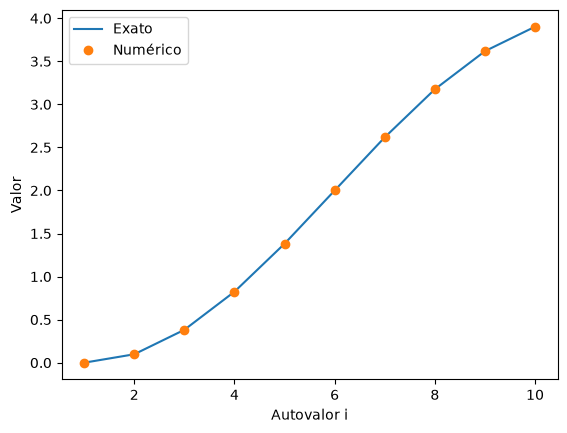

In [3]:
inserir_autovalores(caso1)
inserir_autovalores(caso2)

def exatos_1(n, N):
    return 4 * np.sin(np.pi*(n-1)/(2*N)) ** 2

def exatos_2(n, N):
    return 4 * np.sin(np.pi*n/(2*(N+1))) ** 2

import matplotlib.pyplot as plt

values = np.arange(1, N+1)
plt.plot(values, exatos_1(values, N), label="Exato")
plt.plot(values, caso1["lambda_n"], "o", label="Numérico")
plt.xlabel("Autovalor i")
plt.ylabel("Valor")
plt.legend()
plt.show()
plt.close()

Ao analisar o estado de posições relativas descrito por cada autovetor, obtemos gráficos similares aos harmônicos de ondas estacionárias, como o que ocorre nas cordas de um violão. Isso revela a natureza oscilatória desses estados. Como os autovalores estão em ordem crescente, a frequência aumenta para autovalores maiores, e isso se reflete na quantidade de nós que aparece em cada autovetor.

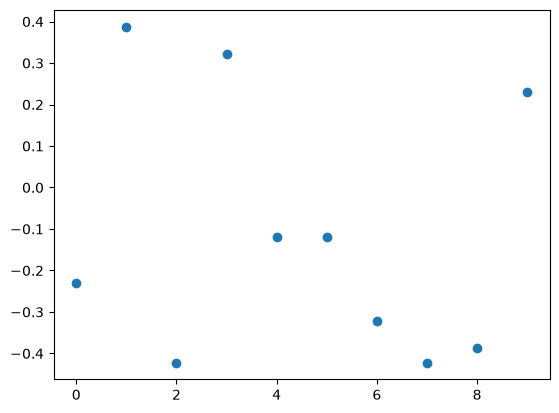

In [4]:
plt.plot(range(N), caso2["u_n"][1], "o")
plt.show()

### 2.c

O vetor destacado representa uma posição em que cada massa possui o mesmo deslocamento em relação à posição original. No caso I, em que $k_i=0$ para todo $i$, isso não afeta o sistema, pois é como se tivéssemos deslocado ele como um todo; como não há influências externas, nada muda. Se, para algum $i$, $k_i\ne 0$ (como no caso II), há uma mola, então isso não é o mesmo que deslocar o sistema inteiro (a mola ligada à massa $i$ está esticada)

$$
\mathsf{A}\,\hat{u}_tr
=
\dfrac{1}{\sqrt{N}}
\begin{bmatrix}
    1 - 1 \\
    -1 + 2 - 1 \\
    -1 + 2 - 1 \\
    \vdots \\
    -1 + 2 - 1 \\
    -1 + 2 - 1 \\
    1 - 1 \\
\end{bmatrix}
=
0
$$

In [5]:
u_tr = np.ones(N) / np.sqrt(N)
caso1["A"] @ u_tr

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

## 3

### 3.a
Queremos mostrar que 
$$x = a_1 \hat{u}_1 + a_2 \hat{u}_2 + \cdots + a_N \hat{u}_N \Rightarrow a_n = \hat{u}_n \cdot x$$
Lembrando que
$$\hat{u}_i \cdot \hat{u}_j = 
\begin{cases}
1 & i = j \\
0 & i \ne j
\end{cases}
$$
Veja que
$$
\begin{align*}
x \cdot u_n
&= a_1 \hat{u}_1 \cdot \hat{u}_n + a_2 \hat{u}_2 \cdot \hat{u}_n + \cdots + a_N \hat{u}_N \cdot \hat{u}_n \\
&= a_1 \cdot 0 + a_2 \cdot 0 + \cdots a_n \cdot 1 + \cdots + a_N \cdot 0 \\
&= a_n
\end{align*}
$$

Aplicando $x=\vec{x}^0$ e $x=\vec{v}^0$, obtemos o que se deseja.

### 3.b

In [6]:
def configurar_estado_inicial(cenario, x_0=None, v_0=None):
    """
    Modifica o dicionário de um cenário, inserindo as posições e velocidades iniciais e os coeficientes correspondentes
    """
    if v_0 is None:
        v_0 = np.zeros(len(cenario["A"]))
    if x_0 is None:
        x_0 = np.zeros(len(cenario["A"]))
    elif type(x_0) is int:
        x_0 = cenario["u_n"][:, x_0]
    cenario["x_0"], cenario["v_0"] = x_0, v_0

    a_0 = cenario["u_n"].T @ x_0
    b_0 = cenario["u_n"].T @ v_0

    cenario["a_0"], cenario["b_0"] = a_0, b_0

configurar_estado_inicial(teste, 1)

print(teste["u_n"] @ teste["a_0"])
print(teste["x_0"])
print(teste["u_n"] @ teste["b_0"])
print(teste["v_0"])

[ 0.682  0.193 -0.154 -0.343 -0.42  -0.335 -0.188 -0.157 -0.074 -0.041]
[ 0.682  0.193 -0.154 -0.343 -0.42  -0.335 -0.188 -0.157 -0.074 -0.041]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 4

### 4.a
O resultado descrito aqui já foi obtido no item 2.a utilizando $u_i$ ao invés de $q_n$, ao explicar o que o espectro significava fisicamente.
$$
\ddot{q}_n = -\dfrac{k}{m}\lambda_n q_n, \quad \omega_n = \sqrt{\frac{k}{m}\lambda_n}

### 4.b
A solução geral para $q_n$ é do tipo
$$q_n(t)=C\,\cos(\omega_nt) + D\sin(\omega_nt)$$
Sabendo que
$$q_n(0)=a_n,$$
temos $C=a_n$ e, dado que
$$\ddot{q}_n(t) = -\omega_n C\cos(\omega_nt) + \omega_n D\sin(\omega_nt) \quad \text{e} \quad \dot{q}_n(t)=b_n,$$
temos $\omega_nD=b_n\Rightarrow D=\frac{b_n}{\omega_n}$. Aplicando à equação para $\vec{x}(t)$ e $\vec{v}(t)$, obtemos
$$\vec{x}(t)=\sum_{n=1}^N
\left(
    a_n,\cos(\omega_nt) + \frac{b_n}{\omega_n}\sin(\omega_nt)
\right)\hat{u}_n
\quad \text{e} \quad
\vec{v}(t)=\sum_{n=1}^N
\bigg(
    -\omega_n a_n,\cos(\omega_nt) + b_n\sin(\omega_nt)
\bigg)\hat{u}_n
$$

### 4.c
Veja que
$$\lim_{\omega_n \to 0} b_n\frac{\sin(\omega_nt)}{w_n} = b_nt$$
e 
$$\lim_{\omega_n \to 0} a_n\cos(\omega_nt) = a_n$$
Portanto,
$$\vec{x}(t)=\sum_{n=1}^N
\left(
    a_n + b_nt
\right)\hat{u}_n
$$
Ou seja, temos um movimento retilíneo uniforme, com posição inicial determinada pelos $a_n$ e velocidade, pelos $b_n$. Tomando $\lambda_n=0$ e utilizando a equação diferencial $m\,\ddot{q}_n=-k\lambda_n q_n$ e seus estados iniciais, obtemos
$$\ddot{q}_n = 0,\quad q_n(0) = a_n \quad \dot{q}_n(0)=b_n$$
confirmando o que obtivemos tomando o limite.

## 5
### 5.a



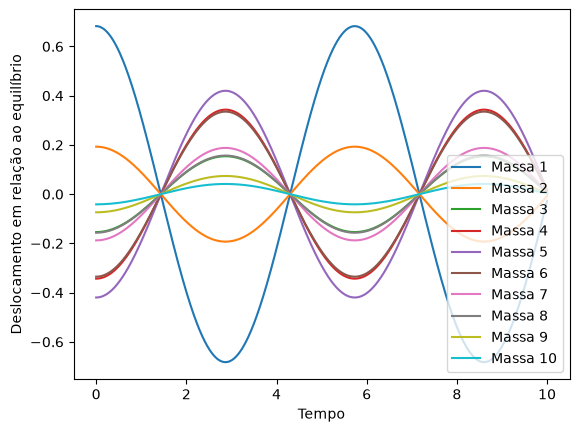

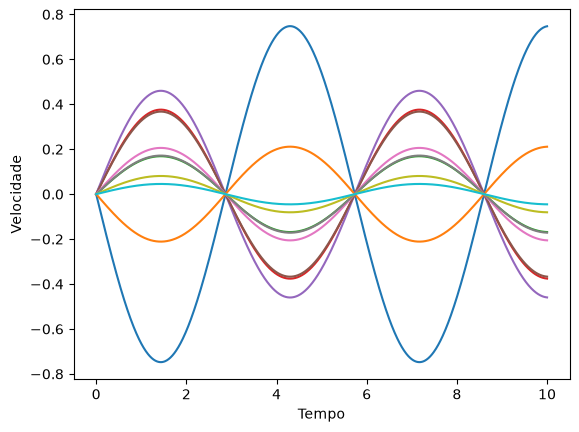

In [7]:
def inserir_omega_n(cenario):
    cenario["omega_n"] = np.sqrt(cenario["k"]/cenario["m"] * cenario["lambda_n"])

inserir_omega_n(teste)

def criar_cenario(N, k_n=None, k=1, x_0=None, v_0=None, m=1, L=1):
    """
    Cria um novo cenário por completo
    """
    cenario = construir_matriz(N, k_n, k, m, L)
    inserir_autovalores(cenario)
    inserir_omega_n(cenario)
    configurar_estado_inicial(cenario, x_0, v_0)

    return cenario

def x_t(cenario, tempo):
    a_0 = cenario["a_0"][:, None]
    b_0 = cenario["b_0"][:, None]
    omega_n = cenario["omega_n"][:, None]
    u_n = cenario["u_n"]

    tol = 1e-10
    zero_mask = (omega_n < tol)
    
    omega_safe = np.where(zero_mask, 1.0, omega_n)
    
    q_osc = a_0 * np.cos(omega_safe * tempo) + (b_0 / omega_safe) * np.sin(omega_safe * tempo)
    q_trans = a_0 + b_0 * tempo
    
    q = np.where(zero_mask, q_trans, q_osc)
    
    return u_n @ q
    

def v_t(cenario, tempo):
    a_0 = cenario["a_0"][:, None]
    b_0 = cenario["b_0"][:, None]
    omega_n = cenario["omega_n"][:, None]
    u_n = cenario["u_n"]

    tol = 1e-10
    zero_mask = (omega_n < tol)

    omega_safe = np.where(zero_mask, 1.0, omega_n)

    q_osc = -omega_n * a_0 * np.sin(omega_safe * tempo) + b_0 * np.cos(omega_safe * tempo)
    q_trans = a_0 + b_0
    
    q = np.where(zero_mask, q_trans, q_osc)
    
    return u_n @ q

instantes = np.linspace(0, 10, 1000)

def descrever_movimento(cenario, instantes):
    x_instantes = x_t(cenario, instantes)
    v_instantes = v_t(cenario, instantes)
    return x_instantes, v_instantes

x, v = descrever_movimento(teste, instantes)

for i, posicao in enumerate(x):
    plt.plot(instantes, posicao, label=f"Massa {i+1}")
plt.legend()
plt.xlabel("Tempo")
plt.ylabel("Deslocamento em relação ao equilíbrio")
plt.show()
plt.close()

for massa in v:
    plt.plot(instantes, massa)
plt.xlabel("Tempo")
plt.ylabel("Velocidade")
plt.show()
plt.close()    

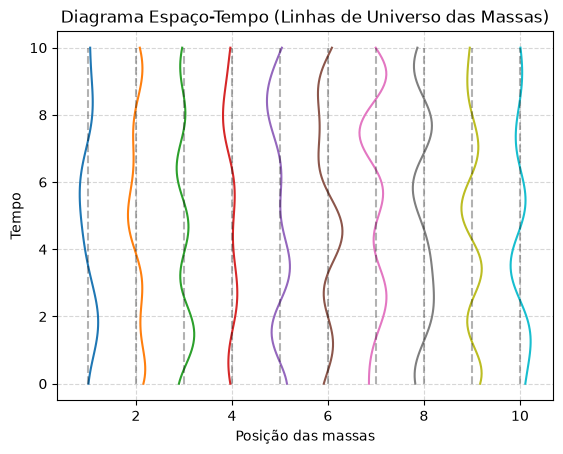

In [8]:
### Utilizando um cenário arbitrário

np.random.seed(10000)

N = 10
abababa = criar_cenario(
    N,
    k_n = np.random.uniform(0, 1, N),
    x_0 = np.random.uniform(-1, 1, N)/5,
    v_0 = np.random.uniform(-1, 1, N)/5
)

instantes2 = np.linspace(0, 10, 100)

x, v = descrever_movimento(abababa, instantes2)


def plot_espaco_tempo(cenario, tempo):
    x, _ = descrever_movimento(cenario, tempo)

    for i, posicao in enumerate(x):
        plt.plot(posicao + (i + 1) * cenario["L"], tempo, label=f"Massa {i+1}")
    for i, posicao in enumerate(x):
        plt.vlines((i+1) * cenario["L"], tempo[0], tempo[-1], colors="black", linestyles="--", alpha=0.3)
    # plt.legend()
    plt.xlabel("Posição das massas")
    plt.ylabel("Tempo")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.title('Diagrama Espaço-Tempo (Linhas de Universo das Massas)')
    plt.show()
    plt.close()

plot_espaco_tempo(abababa, instantes2)

### 5.b

In [9]:
def obter_ep_ideal(cenario):
    A, k, x_0 = cenario["A"], cenario["k"], cenario["x_0"]
    return 0.5 * k * np.dot(x_0, A @ x_0)

def obter_ep(cenario, tempo):
    A, k, x = cenario["A"], cenario["k"], x_t(cenario, tempo)
    return 0.5 * k * np.sum(x * (A @ x), axis=0) 

def obter_ek_ideal(cenario):
    m, v_0 = cenario["m"], cenario["v_0"]
    return 0.5 * m * np.sum(v_0**2)

def obter_ek(cenario, tempo):
    m, v = cenario["m"], v_t(cenario, tempo)
    return 0.5 * m * np.sum(v * v, axis=0)

def obter_em(cenario, tempo):
    return obter_ep(cenario, tempo) + obter_ek(cenario, tempo)
def obter_em_ideal(cenario):
    return obter_ep_ideal(cenario) + obter_ek_ideal(cenario)

print(obter_em_ideal(teste))
print(obter_em(teste, [1, 2, 3]))

0.6001705167654354
[0.6 0.6 0.6]


### 5.c

In [10]:
# Dividir pelo coeficiente da amplitude parece não ter funcionado bem nos casos em que a massa se encontra perto
# do ponto de equilíbrio. Os outros casos parecem funcionar bem
for n in range(1, 5):
    cenario = criar_cenario(10, x_0=n)
    for i in range(8):
        t = i * np.pi / (4 * cenario["omega_n"][n])
        print(x_t(cenario, t).T[0] / np.cos(cenario["omega_n"][n] * t))
    print("-----------------------------------------------------------------------")
    print(cenario["u_n"][:, n])
    print("=======================================================================")

[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[ 2.239 -1.302 -0.867  1.293 -3.166  1.135 -0.298 -2.363  3.204  1.559]
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[-0.734 -1.312  0.072  0.362  0.211 -0.074  0.46   0.685 -0.579  0.431]
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
-----------------------------------------------------------------------
[-0.442 -0.398 -0.316 -0.203 -0.07   0.07   0.203  0.316  0.398  0.442]
[ 0.425  0.263 -0.    -0.263 -0.425 -0.425 -0.263  0.     0.263  0.425]
[ 0.425  0.263 -0.    -0.263 -0.425 -0.425 -0.263  0.     0.263  0.425]
[ 0.11   0.525  0.365 -0.113 -0.335 -0.567 -0.723 -0.458  0.208  0.37 ]
[ 0.425  0.263 -0.    -0.263 -0.425 -0.425 -0.263  0.     0.263 

### 5.d

Note que o plot no espaço-tempo já foi feito em 5.a

In [11]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animar_massas(x_matrix, cenario):
    L = cenario["L"]
    N, T = x_matrix.shape
    pos_eq = np.arange(1, N + 1) * L
    
    fig, ax = plt.subplots(figsize=(12, 2))
    
    max_deslocamento = np.max(np.abs(x_matrix))
    ax.set_xlim(pos_eq[0] - max_deslocamento - 0.5, pos_eq[-1] + max_deslocamento + 0.5)
    
    ax.set_ylim(-1, 1)
    ax.set_yticks([]) 
    ax.set_xlabel("Posição Real ($x$)")
    ax.set_title("Movimento das Massas (1D)")
    ax.grid(True, axis='x', linestyle='--', alpha=0.7)
    
    pontos, = ax.plot([], [], 'o', color='royalblue', markersize=8)
    
    def init():
        pontos.set_data([], [])
        return (pontos,)
    
    def animate(frame):
        pos_real = pos_eq + x_matrix[:, frame]
        pontos.set_data(pos_real, np.zeros(N))
        return (pontos,)
    
    passo_frame = max(1, T // 200) 
    
    ani = FuncAnimation(fig, animate, init_func=init,
                        frames=np.arange(0, T, passo_frame), 
                        interval=50, blit=True)
    
    plt.close(fig) 

    return HTML(ani.to_jshtml())

display(animar_massas(x, abababa))

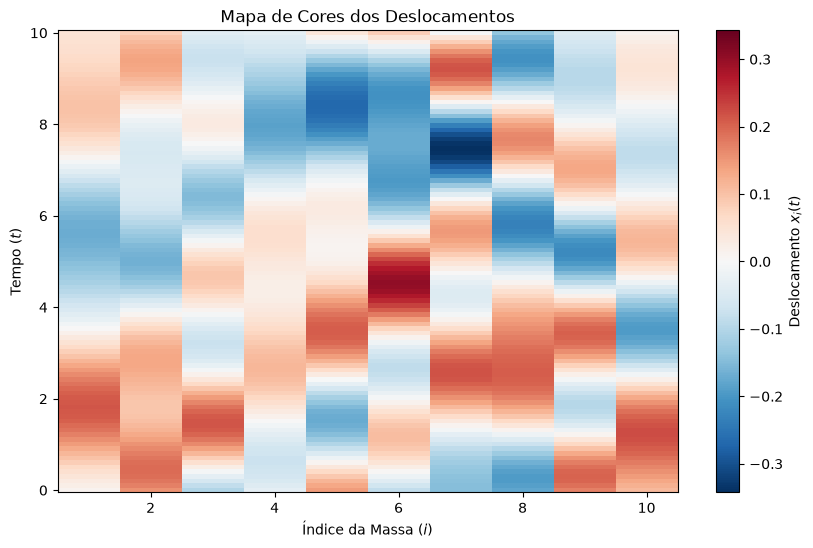

In [12]:
def plot_mapa_cores(x_matrix, tempos):
    N, T = x_matrix.shape
    
    # Cria um array com os índices das massas (1 até N)
    massas = np.arange(1, N + 1)
    
    plt.figure(figsize=(10, 6))
    
    # pcolormesh desenha a grade de cores. 
    # Passamos x_matrix.T (transposta) porque a função espera o formato (tempo, massas) 
    # para bater com os eixos Y e X, respectivamente.
    # O colormap 'RdBu_r' (Red-Blue invertido) é divergente: centra o branco no zero.
    
    # Para garantir que o branco seja exatamente zero, definimos vmin e vmax simétricos
    limite = np.max(np.abs(x_matrix))
    mapa = plt.pcolormesh(massas, tempos, x_matrix.T, 
                          cmap='RdBu_r', vmin=-limite, vmax=limite, shading='auto')
    
    # Adiciona a barra lateral para interpretar as cores
    cbar = plt.colorbar(mapa)
    cbar.set_label('Deslocamento $x_i(t)$')
    
    plt.xlabel('Índice da Massa ($i$)')
    plt.ylabel('Tempo ($t$)')
    plt.title('Mapa de Cores dos Deslocamentos')
    
    # Opcional: inverte o eixo Y para o tempo crescer de cima para baixo
    # plt.gca().invert_yaxis()
    
    plt.show()

plot_mapa_cores(x, instantes2)

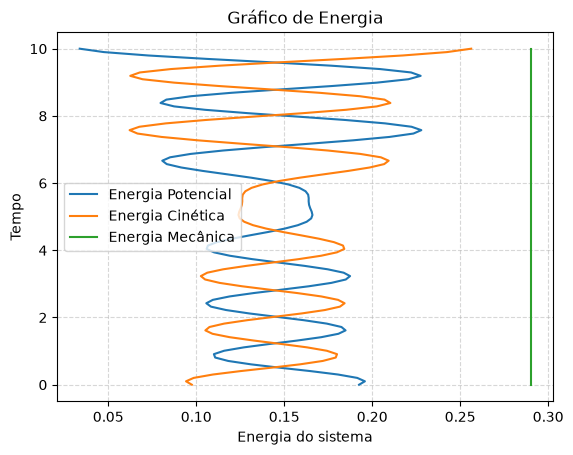

In [13]:
def plot_energia(cenario, tempo):
    ep = obter_ep(cenario, tempo)
    ek = obter_ek(cenario, tempo)

    plt.plot(ep, tempo, label=f"Energia Potencial")
    plt.plot(ek, tempo, label=f"Energia Cinética")
    plt.plot(ek + ep, tempo, label=f"Energia Mecânica")
    plt.legend()
    plt.xlabel("Energia do sistema")
    plt.ylabel("Tempo")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.title('Gráfico de Energia')
    plt.show()
    plt.close()

plot_energia(abababa, instantes2)

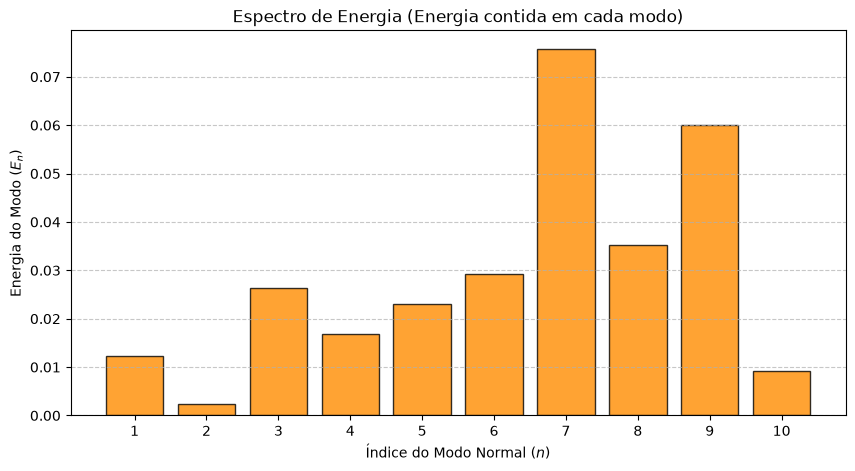

In [14]:
def plot_energia_modos(cenario):
    a_0 = cenario["a_0"]
    b_0 = cenario["b_0"]
    omega_n = cenario["omega_n"]
    m = cenario["m"]
    
    energia_modos = 0.5 * m * (b_0**2) + 0.5 * m * (omega_n**2) * (a_0**2)
    
    modos = np.arange(1, len(omega_n) + 1)
    
    plt.figure(figsize=(10, 5))
    
    plt.bar(modos, energia_modos, color='darkorange', edgecolor='black', alpha=0.8)
    
    plt.xlabel('Índice do Modo Normal ($n$)')
    plt.ylabel('Energia do Modo ($E_n$)')
    plt.title('Espectro de Energia (Energia contida em cada modo)')
    
    plt.xticks(modos)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    plt.show()

plot_energia_modos(abababa)

## 6

### 6.a

In [15]:
v_colisao = 5
N_colisao = 50
k_n_colisao = np.zeros(N_colisao)
k_n_colisao[-1] += 5
cenario_parede = criar_cenario(N_colisao, k_n=k_n_colisao, k=5, x_0=np.zeros(N_colisao), v_0=np.full(N_colisao, v_colisao), m=2, L=10)

tempos_teste = np.linspace(0, 150, 5000)

x_matrix = x_t(cenario_parede, tempos_teste)

x_N = x_matrix[-1, :]

cruzou_zero = (x_N < 0) & (tempos_teste > 0.1) 

indice_desc = np.argmax(cruzou_zero)
t_desc = tempos_teste[indice_desc]

tempos_contato = tempos_teste[:indice_desc]
x_contato = x_matrix[:, :indice_desc]

display(animar_massas(x_contato, cenario_parede))

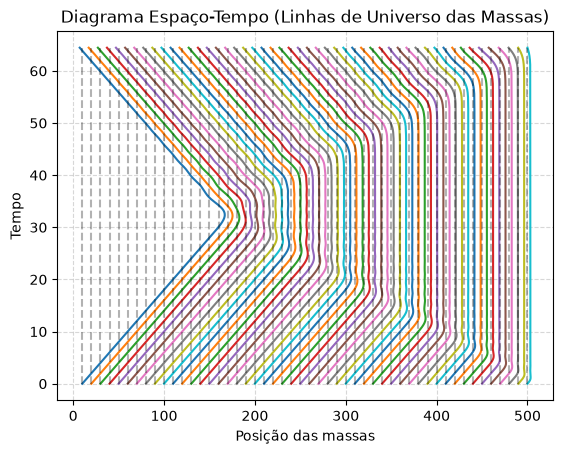

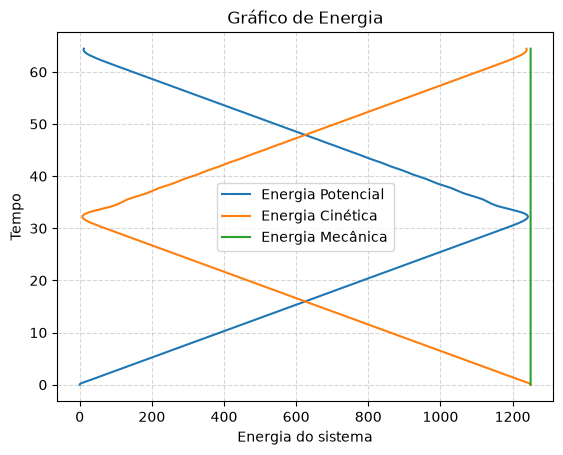

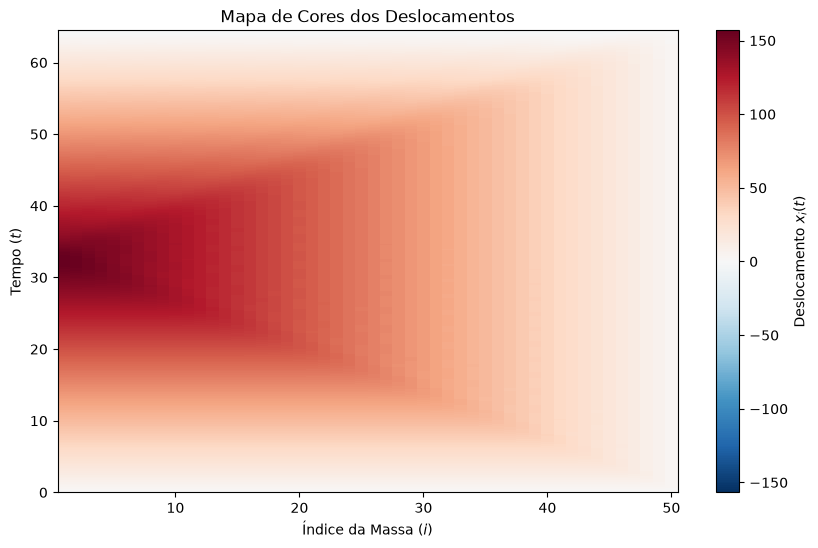

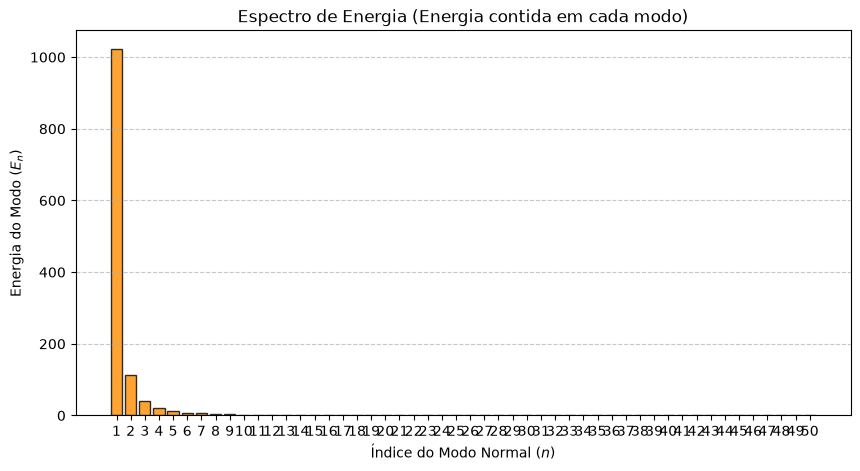

In [16]:
plot_espaco_tempo(cenario_parede, tempos_contato)
plot_energia(cenario_parede, tempos_contato)
plot_mapa_cores(x_contato, tempos_contato)
plot_energia_modos(cenario_parede)

In [17]:
def calcular_c_estimado(v_fisico_inicial, L, m, k):
    # Usamos a velocidade física real com que as massas começaram
    limiar = 0.95 * v_fisico_inicial
    
    # Gera a matriz de velocidades
    v_matrix = v_t(cenario_parede, tempos_contato)

    # Encontra onde a velocidade cai abaixo do limiar
    caiu_velocidade = v_matrix < limiar

    # O argmax encontra o primeiro índice (instante de tempo) onde isso é True
    indices_chegada = np.argmax(caiu_velocidade, axis=1)

    # Extrai os tempos correspondentes
    tempos_chegada = tempos_contato[indices_chegada]

    # Distância percorrida pelo sinal (da massa N até a massa 1)
    # Lembre-se que o roteiro sugeriu L=1 no item 5.a, mas vi que usou L=10.
    N = 50
    distancia = (N - 1) * L

    # delta_t = instante em que a massa 1 sentiu - instante em que a massa N sentiu
    delta_t = tempos_chegada[0] - tempos_chegada[-1]

    c_estimado = distancia / delta_t
    
    print(f"Velocidade estimada (c): {c_estimado:.4f}")
    print(f"Velocidade teórica (c): {np.sqrt(k * L**2 / m):.4f}")

calcular_c_estimado(v_fisico_inicial=5, L=10, m=2, k=5)

Velocidade estimada (c): 16.6125
Velocidade teórica (c): 15.8114


Nesse caso, a discrepância ocorre pois o modelo teórico exige que o sistema seja um meio continuo. Aqui, ao discretizá-lo em N massas, 